# Vergelijking van vier schaalvarianten — 100 epochs

**SVHN train-only · CNN-8 (`svhnq`, expand 2) · E4M3 / E2M3 / E2M1 · A32 · FP32-master**

We vergelijken de bestaande resultaten van vaste **×64**, vaste **×32**, een **geleerde ×32/×64-keuze per MX-blok**, en dezelfde geleerde training met **vaste offsets na epoch 50**. De laatste variant deelt de eerste 50 epochs met de geleerde training en vormt daarna een vertakking.

Dit document leest de meegeleverde resultaten. Er wordt geen training gestart en er worden geen binaire checkpoints of datasets geladen. De E4M3-bronschaal blijft in alle varianten uit de actuele gewichten berekend; de extra offset is vast of geleerd.

## Werkwijze en selectieregels

1. **Primair: epoch 100**, het gemeenschappelijke eindpunt.
2. **Globale selectie: hoogste E4M3-testaccuracy binnen 1–100**. Alle drie precisies van een variant worden op diezelfde geselecteerde epoch vergeleken; bij gelijke maxima geldt de eerste epoch.
3. **Aanvullend: hoogste E4M3-testaccuracy binnen 51–100**, met hetzelfde venster voor alle vier varianten.

Er wordt geen afzonderlijk beste checkpoint per lagere precisie gekozen. De testset is ook voor selectie gebruikt; deze geselecteerde scores zijn daardoor geen onafhankelijke validatieschatting. De runs gebruiken dezelfde seed en basisinitialisatie. CUDA is niet bitexact gegarandeerd en de bevroren variant is geen onafhankelijke vierde initialisatie.

In [1]:
from pathlib import Path

# Normaal kan dit blijven staan. Voor een andere locatie: BASE_DIR = Path(r"C:\pad\naar\mx_scale_variants_comparison100_v1")
BASE_DIR = Path.cwd()
SAVE_FIGURES = False  # Alleen True zetten als je PNG-bestanden naast de notebook wilt bewaren.

In [2]:
import importlib.util
import sys
from IPython.display import display
from IPython import get_ipython
import matplotlib.pyplot as plt

if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")

candidates = [BASE_DIR, BASE_DIR / "mx_scale_variants_comparison100_v1",
              BASE_DIR / "software_checks" / "mx_scale_variants_comparison100_v1"]
BASE_DIR = next((p.resolve() for p in candidates if (p / "SOURCE_MANIFEST.json").is_file()
                 and (p / "comparison_support.py").is_file()), None)
if BASE_DIR is None:
    raise FileNotFoundError("Pakketmap niet gevonden. Vul BASE_DIR in de parametercel in en voer opnieuw uit.")

spec = importlib.util.spec_from_file_location("mx_scale_variants_comparison100_support", BASE_DIR / "comparison_support.py")
comparison_support = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = comparison_support
spec.loader.exec_module(comparison_support)
comparison = comparison_support.load_comparison(BASE_DIR)
figures = {}
print("Resultaten geladen en gecontroleerd uit:", BASE_DIR)
print("Geen nieuwe training of checkpoint-evaluatie uitgevoerd.")

Resultaten geladen en gecontroleerd uit: C:\Users\renzo\master-thesis-mx\software_checks\mx_scale_variants_comparison100_v1
Geen nieuwe training of checkpoint-evaluatie uitgevoerd.


## 1. Beschikbaarheid en integriteit

De helper controleert de bronhashes, echte voltooiing tot epoch 100, het gemeenschappelijke protocol, A32/FP32, volledige metrics, learning rates, accuracies tegenover gehele juiste-aantallen, en alle opgeslagen selecties. De eerste 50 epochs van het bevroren traject komen uitsluitend uit de gedeelde geleerde voorgeschiedenis; vanaf epoch 51 worden de eigen bevroren metingen gebruikt.

De historische ×32-referentie bevat alle epochmetrics en de oorspronkelijke rapporten. De volledige per-minibatchhistoriek van die run is voor dit overzicht niet nodig en wordt hier niet opnieuw gecontroleerd.

In [3]:
display(comparison.availability())
for check in comparison.checks:
    print("✓", check)

,Variant,Voltooide eindepoch,Eigen gemeten epochs,Globaal E4M3-best,E4M3-best 51–100,Nieuwe training nodig
0,Vast ×64,100,1–100,42,61,Nee
1,Vast ×32,100,1–100,55,55,Nee
2,Geleerd tot 100,100,1–100,34,51,Nee
3,Geleerd; vast na 50,100,51–100; 1–50 gedeeld,34,51,Nee


✓ 28 bronbestanden gecontroleerd op SHA256
✓ Vast ×64: compleet, echt, correcte A32/FP32-metrics en LR
✓ Vast ×32: compleet, echt, correcte A32/FP32-metrics en LR
✓ Geleerd tot 100: compleet, echt, correcte A32/FP32-metrics en LR
✓ Geleerd; vast na 50: compleet, echt, correcte A32/FP32-metrics en LR
✓ Gemeenschappelijk protocol en basisinitialisatie gecontroleerd
✓ Freeze-afstamming, vaste blokkeuzes en dynamische bronschaal gecontroleerd
✓ Alle drie selecties herberekend; alle opgeslagen geselecteerde scores sluiten aan


## 2. Gemeenschappelijk eindpunt: epoch 100

Deze vergelijking gebruikt voor alle varianten precies epoch 100. De figuur gebruikt een duidelijk aangegeven uitvergrote y-as om de kleine accuracyverschillen leesbaar te maken. De tabel bevat de preciezere waarden.

,Variant,Epoch,E4M3 (%),E2M3 (%),E2M1 (%),Herkomst
0,Vast ×64,100,"94,9293","94,8986","94,7910",Eigen training
1,Vast ×32,100,"94,7065","94,8525","94,9140",Eigen training
2,Geleerd tot 100,100,"94,9332","94,1764","93,9498",Eigen training
3,Geleerd; vast na 50,100,"94,7757","94,7142","94,5260",Bevroren fase


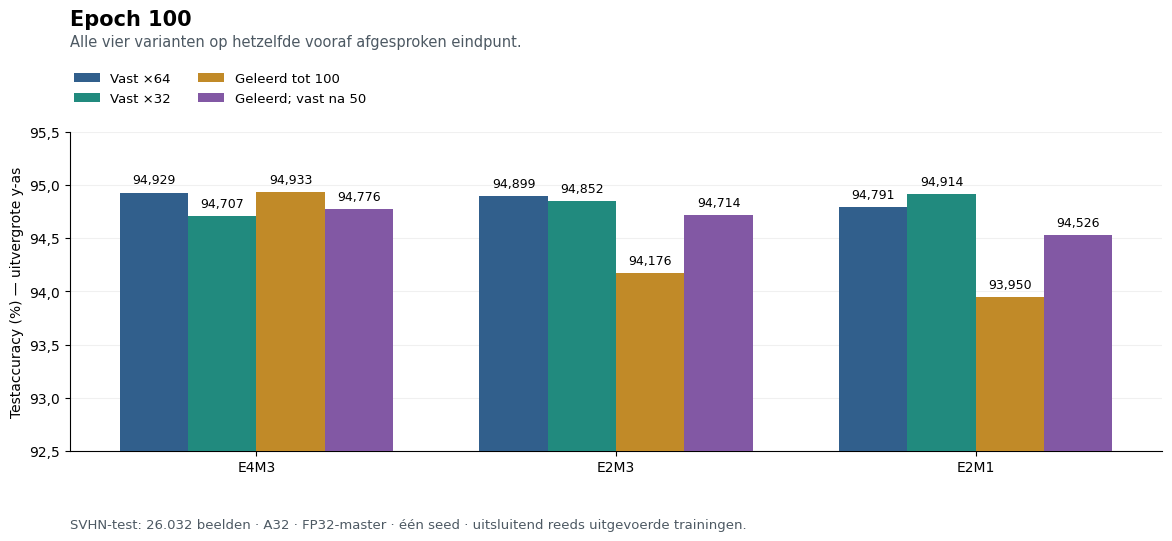

In [4]:
display(comparison_support.styled_table(comparison.table("epoch100")))
figures["01_epoch100"] = comparison_support.selection_figure(comparison, "epoch100")
plt.show()

### Verschillen ten opzichte van vaste ×64

Een positief verschil betekent een hogere accuracy dan vaste ×64; een negatief verschil betekent een lagere accuracy. Het zijn **procentpunten**. Dit is een vergelijking per precisie, zonder een zelfgekozen gemiddelde over de drie modi.

In [5]:
display(comparison_support.styled_table(comparison.differences(reference="fixed64", role="epoch100")))

,Variant,E4M3 (procentpunt),E2M3 (procentpunt),E2M1 (procentpunt)
0,Vast ×64,"0,0000","0,0000","0,0000"
1,Vast ×32,"-0,2228","-0,0461","0,1229"
2,Geleerd tot 100,"0,0038","-0,7222","-0,8413"
3,Geleerd; vast na 50,"-0,1537","-0,1844","-0,2651"


## 3. Gebruikelijke globale E4M3-selectie: epochs 1–100

De gekozen epoch mag per variant verschillen. Binnen één variant gebruiken E4M3, E2M3 en E2M1 altijd hetzelfde geselecteerde checkpoint.

**De geleerde en bevroren variant selecteren hier beide epoch 34.** Zij tonen daardoor exact hetzelfde model uit hun gemeenschappelijke fase vóór de freeze. Deze gelijke scores zijn geen meting van het effect van vastzetten na epoch 50.

,Variant,Epoch,E4M3 (%),E2M3 (%),E2M1 (%),Herkomst
0,Vast ×64,42,"95,0868","93,8422","93,9229",Eigen training
1,Vast ×32,55,"94,8448","95,0061","94,7757",Eigen training
2,Geleerd tot 100,34,"95,0138","93,1930","93,5925",Eigen training
3,Geleerd; vast na 50,34,"95,0138","93,1930","93,5925",Gedeelde voorfase


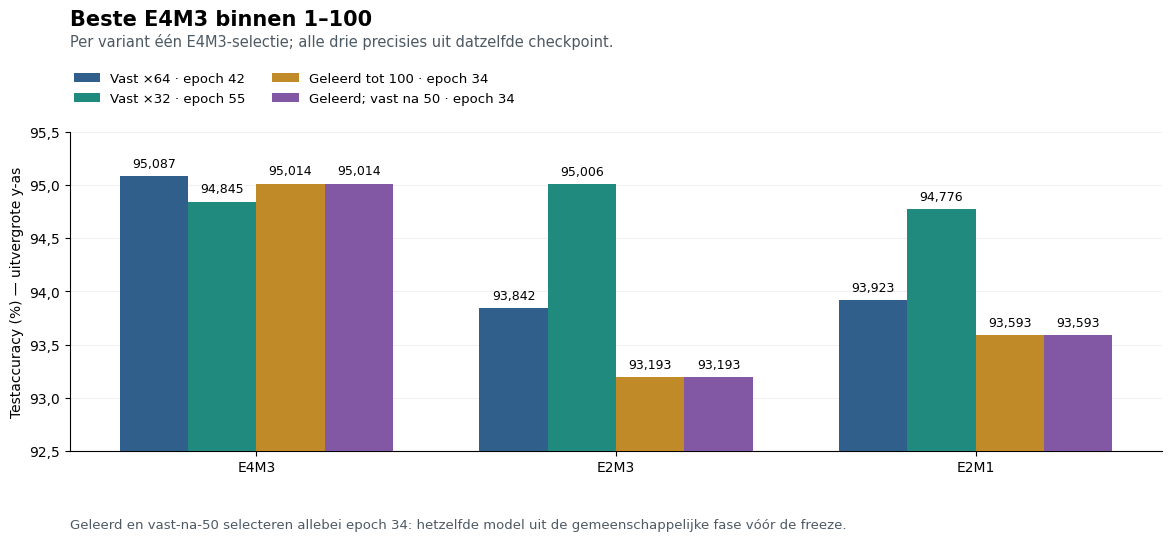

In [6]:
display(comparison_support.styled_table(comparison.table("global_best")))
figures["02_globaal_E4M3_best"] = comparison_support.selection_figure(comparison, "global_best")
plt.show()

## 4. Aanvullende selectie in hetzelfde late venster: epochs 51–100

Voor alle vier varianten wordt de hoogste E4M3-accuracy uitsluitend binnen 51–100 gekozen. Dit maakt de latere fase zichtbaar, inclusief de bevroren voortzetting. Deze aanvullende analyse vervangt de globale selectieregel hierboven niet.

,Variant,Epoch,E4M3 (%),E2M3 (%),E2M1 (%),Herkomst
0,Vast ×64,61,"95,0446","94,5567","94,5836",Eigen training
1,Vast ×32,55,"94,8448","95,0061","94,7757",Eigen training
2,Geleerd tot 100,51,"94,9524","93,9690","93,8076",Eigen training
3,Geleerd; vast na 50,51,"94,9140","94,3723","94,2609",Bevroren fase


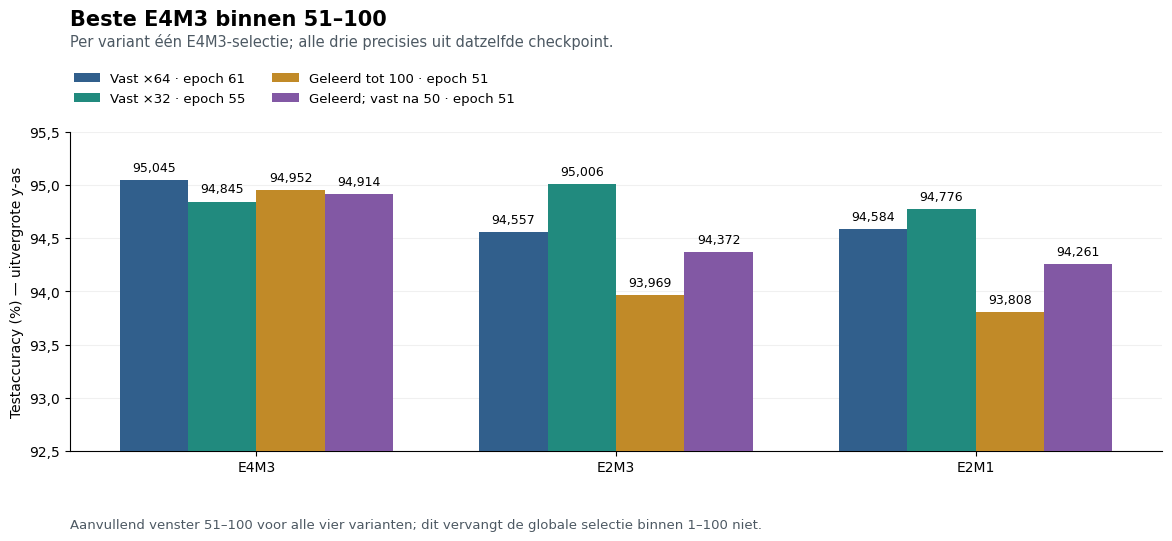

In [7]:
display(comparison_support.styled_table(comparison.table("window51_best")))
figures["03_E4M3_best_51_100"] = comparison_support.selection_figure(comparison, "window51_best")
plt.show()

## 5. Volledige accuracycurves

De geleerde en bevroren variant delen exact dezelfde metingen tot en met epoch 50. Daarom wordt de paarse bevroren lijn pas vanaf dat gezamenlijke anker zichtbaar. Alle gemeten epochs worden getoond; de lijnen zijn niet gladgestreken.

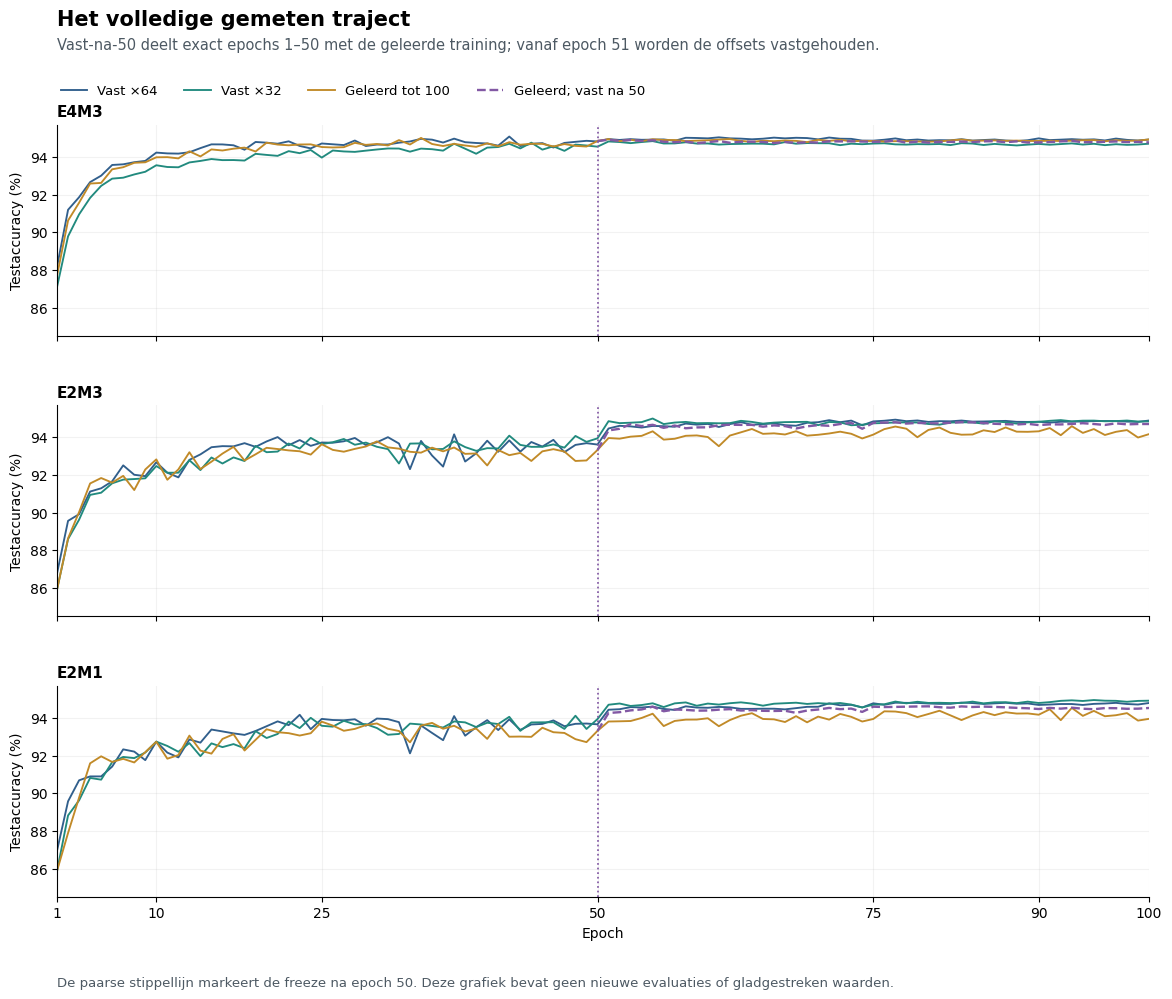

In [8]:
figures["04_accuracycurves"] = comparison_support.curves_figure(comparison)
plt.show()

## 6. Extra schaaltoestand en interpretatie van kosten

Onderstaande aantallen beschrijven alleen de **extra toestand voor de keuze tussen ×32 en ×64**. De normale E8M0-bronschalen en de overige modeltoestand bestaan daarnaast in alle varianten.

In de compacte geleerde export volstaat één keuzebit per MX-blok: 4.080 bits = 510 bytes. Tijdens training blijven de FP32-theta's en bijbehorende optimizerstaat aanwezig. In de uitgevoerde freeze-proef worden theta-gradients en Adam-momenten nog berekend met theta-LR nul. De gemeten looptijden bewijzen dus geen geoptimaliseerde besparing door het stoppen met schaalupdates.

In [9]:
display(comparison_support.cost_table())

,Variant,Extra FP32-theta’s tijdens training,Extra blokkeuzes in compacte export,Offsetbeleid
0,Vast ×64,0,0; factor is globaal vast,Altijd +6 (×64)
1,Vast ×32,0,0; factor is globaal vast,Altijd +5 (×32)
2,Geleerd tot 100,4080,4080 bits = 510 bytes,+5/+6 per blok; leren tot 100
3,Geleerd; vast na 50,4080,4080 bits = 510 bytes,"+5/+6 leren tot 50, daarna vast"


## 7. Figuren bewaren (optioneel)

Met `SAVE_FIGURES = True` in de parametercel worden de vier figuren als PNG opgeslagen onder `figures` in deze pakketmap. De oorspronkelijke resultaten blijven ongewijzigd.

In [10]:
if SAVE_FIGURES:
    figure_dir = BASE_DIR / "figures"
    figure_dir.mkdir(exist_ok=True)
    for name, figure in figures.items():
        figure.savefig(figure_dir / (name + ".png"), dpi=200, bbox_inches="tight")
    print("Figuren opgeslagen in:", figure_dir)
else:
    print("Figuren niet naar bestanden geschreven; ze staan hierboven in de notebook.")

Figuren niet naar bestanden geschreven; ze staan hierboven in de notebook.


## Beoordeling van deze bestaande runs

- Op **epoch 100** scoort vaste ×64 hoger dan de bevroren geleerde variant bij **alle drie precisies**. De freeze verbetert de volledig geleerde aanpak bij de twee lagere precisies, maar toont hier geen meerwaarde boven de vaste ×64-factor.
- Vaste ×32 geeft op epoch 100 de hoogste E2M1-accuracy van deze vier varianten. Vaste ×64 geeft de hoogste E2M3-accuracy. De geleerde variant heeft de hoogste E4M3-score, met slechts één juiste testvoorspelling meer dan vaste ×64.
- De **globale E4M3-selectie** geeft een andere afweging: vaste ×64 selecteert epoch 42, vaste ×32 epoch 55, en beide geleerde trajecten het gemeenschappelijke checkpoint 34. Daarom moeten eindpunt en selectie naast elkaar blijven staan.
- De resultaten tonen wat deze concrete runs opleveren. Ze bewijzen geen universeel optimale factor, optimaal freeze-moment of herhaalbaarheid over onafhankelijke seeds/workloads.

**Conclusie voor deze vergelijking:** de bestaande metingen zijn voldoende om de vier aanpakken nu naast elkaar te zetten. Daarvoor zijn geen nieuwe trainingsruns of checkpoint-evaluaties nodig.